# Blue Whale Heart Rates

By how much do blue whale heart rates change when they dive down to find food? 

The file `blue-whale-heart-rates.csv` contains heart rate data (measured in beats per minute) for blue whales. The data captures the dynamics of their heart rates as they dive over one hundred meters deep to forage for food. The heart rate measurements are taken approximately every 10 seconds during 8 separate dives.

### Dive Phases
The data records the heart rates corresponding to different dive states:
1. Descent: The whale begins its dive, descending into the depths.
2. Lunging: The whale opens its mouth and lunges upward, engulfing prey and water.
3. Filtering: After lunging, the whale sinks slightly and filters out water to retain food.
4. Ascent: The whale returns to the surface to breathe, marking the end of a dive.
5.  Surface: The blue whale is now on the surface (upper 5 meters)

The lunging and filtering process may occur multiple times on a single dive. The next dive cycle begins with another descent.

In [1]:
# FOR GOOGLE COLAB ONLY.
# Uncomment and run the code below. A dialog will appear to upload files.
# Upload 'blue-whale-heart-rates.csv'.

# from google.colab import files
# uploaded = files.upload()

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('blue-whale-heart-rates.csv')
df.head()


,timestamp,heart_rate,dive_id,dive_phase
0,8/27/18 17:10:10,NaN,2,descent
1,8/27/18 17:10:22,5.24,2,descent
2,8/27/18 17:10:31,6.55,2,descent
3,8/27/18 17:10:40,NaN,2,descent
4,8/27/18 17:10:48,NaN,2,descent


### Project Ideas

#### Warmup
Calculate the average heart rates for each dive phase.

#### Challenge
Investigate the relationship between dive duration and the maximum heart rate at the surface following the dive.

1. Data Preparation:
	- Convert the `timestamp` column to datetime format.

2. Calculate Dive Duration:
	- For each `dive_id`, identify the earliest timestamp for the descent phase.
	- For each `dive_id`, find the latest timestamp for the ascent phase.
	- Compute the `dive_duration` by subtracting the start of the descent from the end of the ascent, then convert this duration to minutes (`dt.total_seconds() / 60`).
	- Store the results in a new dataframe with 2 columns: `dive_id` and `dive_duration`.

3. Determine Maximum Surface Heart Rate:
	- Identify the maximum heart rate recorded at the surface after each dive.
	- Store the results in a new dataframe with 2 columns: `dive_id` and `max_surface_heart_rate`

4. Merge DataFrames:
	- Merge the dive duration and max surface heart rate dataframes.
	
5.	Visualize the Data:
	- Generate a scatter plot with dive duration on the x-axis and maximum surface heart rate on the y-axis to illustrate their relationship.

## Lösung

### Warmup

Calculate the average heart rates for each dive phase.

In [3]:
import doctest


def average_heart_rates(data: pd.DataFrame) -> pd.Series:
    """Liefert die durchschnittliche Herzfrequenz pro Tauchphase (NaN wird ignoriert).

    >>> toy = pd.DataFrame({"dive_phase": ["a", "a", "a", "b"], "heart_rate": [2, 4, None, 10]})
    >>> average_heart_rates(toy).to_dict()
    {'a': 3.0, 'b': 10.0}
    """
    return data.groupby("dive_phase")["heart_rate"].mean()


average_heart_rates(df).round(2)

dive_phase
ascent     20.43
descent     7.47
filter      6.56
lunge       9.77
surface    32.55
Name: heart_rate, dtype: float64

**Antwort:** An der Oberfläche ist der Puls am höchsten, beim Filtern am niedrigsten.

### Challenge

Investigate the relationship between dive duration and the maximum heart rate at the surface following the dive.

#### 1. Data Preparation

In [6]:
# Die Zeitstempel haben das US-Format Monat/Tag/Jahr, z. B. 8/27/18 17:10:10
df["timestamp"] = pd.to_datetime(df["timestamp"], format="%m/%d/%y %H:%M:%S")
df["timestamp"].dtype

dtype('<M8[us]')

#### 2. Calculate Dive Duration

In [7]:
def dive_durations(data: pd.DataFrame) -> pd.DataFrame:
    """Liefert pro Tauchgang die Dauer in Minuten, vom ersten descent bis zum letzten ascent.

    >>> toy = pd.DataFrame({
    ...     "dive_id": [1, 1, 1, 1],
    ...     "dive_phase": ["descent", "descent", "ascent", "surface"],
    ...     "timestamp": pd.to_datetime(["2018-08-27 10:00:00", "2018-08-27 10:01:00",
    ...                                  "2018-08-27 10:06:30", "2018-08-27 10:09:00"]),
    ... })
    >>> dive_durations(toy).to_dict("records")
    [{'dive_id': 1, 'dive_duration': 6.5}]
    """
    start = data[data["dive_phase"] == "descent"].groupby("dive_id")["timestamp"].min()
    end = data[data["dive_phase"] == "ascent"].groupby("dive_id")["timestamp"].max()
    duration = (end - start).dt.total_seconds() / 60
    return duration.rename("dive_duration").reset_index()


durations = dive_durations(df)
durations

,dive_id,dive_duration
0,2,12.433333
1,3,12.400000
2,4,9.000000
3,5,9.616667
4,7,11.216667
5,10,11.016667
6,11,16.400000
7,13,10.916667


#### 3. Determine Maximum Surface Heart Rate

In [8]:
def max_surface_heart_rates(data: pd.DataFrame) -> pd.DataFrame:
    """Liefert pro Tauchgang die höchste Herzfrequenz an der Oberfläche (NaN wird ignoriert).

    >>> toy = pd.DataFrame({
    ...     "dive_id": [1, 1, 1, 2],
    ...     "dive_phase": ["surface", "surface", "ascent", "surface"],
    ...     "heart_rate": [30, None, 99, 20],
    ... })
    >>> max_surface_heart_rates(toy).to_dict("records")
    [{'dive_id': 1, 'max_surface_heart_rate': 30.0}, {'dive_id': 2, 'max_surface_heart_rate': 20.0}]
    """
    surface = data[data["dive_phase"] == "surface"]
    highest = surface.groupby("dive_id")["heart_rate"].max()
    return highest.rename("max_surface_heart_rate").reset_index()


surface_rates = max_surface_heart_rates(df)
surface_rates

,dive_id,max_surface_heart_rate
0,2,35.50
1,3,35.29
2,4,34.48
3,5,33.90
4,7,33.52
5,10,35.29
6,11,38.22
7,13,34.88


#### 4. Merge DataFrames

In [9]:
def merge_dive_data(durations: pd.DataFrame, surface_rates: pd.DataFrame) -> pd.DataFrame:
    """Führt die beiden Tabellen über dive_id zusammen.

    >>> left = pd.DataFrame({"dive_id": [1, 2], "dive_duration": [6.5, 9.0]})
    >>> right = pd.DataFrame({"dive_id": [1, 2], "max_surface_heart_rate": [30.0, 20.0]})
    >>> merge_dive_data(left, right).to_dict("records")[0]
    {'dive_id': 1, 'dive_duration': 6.5, 'max_surface_heart_rate': 30.0}
    """
    return pd.merge(durations, surface_rates, on="dive_id")


merged = merge_dive_data(durations, surface_rates)
merged

,dive_id,dive_duration,max_surface_heart_rate
0,2,12.433333,35.50
1,3,12.400000,35.29
2,4,9.000000,34.48
3,5,9.616667,33.90
4,7,11.216667,33.52
5,10,11.016667,35.29
6,11,16.400000,38.22
7,13,10.916667,34.88


#### 5. Visualize the Data

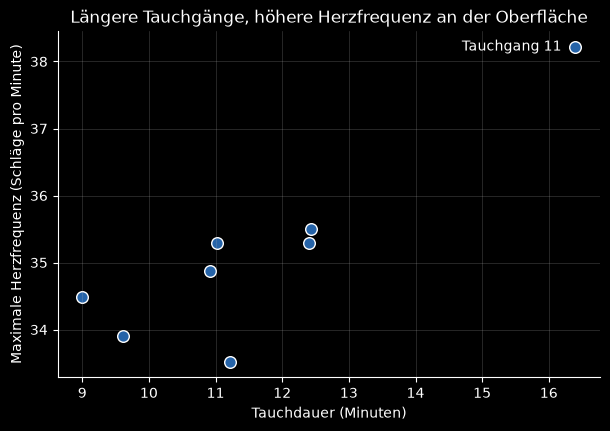

Korrelation alle Tauchgänge:  0.88
Korrelation ohne den längsten: 0.56


In [11]:
def plot_dive_relationship(data: pd.DataFrame) -> plt.Axes:
    """Zeichnet die Tauchdauer gegen die höchste Herzfrequenz und beschriftet den längsten Tauchgang.

    >>> toy = pd.DataFrame({"dive_id": [1, 2], "dive_duration": [6.5, 9.0], "max_surface_heart_rate": [30.0, 20.0]})
    >>> ax = plot_dive_relationship(toy)
    >>> ax.get_xlabel(), len(ax.texts)
    ('Tauchdauer (Minuten)', 1)
    >>> plt.close(ax.figure)
    """
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.scatter(data["dive_duration"], data["max_surface_heart_rate"], s=70, color="#2563a8", edgecolor="white")

    longest = data.loc[data["dive_duration"].idxmax()]
    ax.annotate(f"Tauchgang {int(longest['dive_id'])}", (longest["dive_duration"], longest["max_surface_heart_rate"]),
                xytext=(-10, 0), textcoords="offset points", ha="right", va="center")

    ax.set_title("Längere Tauchgänge, höhere Herzfrequenz an der Oberfläche")
    ax.set_xlabel("Tauchdauer (Minuten)")
    ax.set_ylabel("Maximale Herzfrequenz (Schläge pro Minute)")
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    return ax


plot_dive_relationship(merged)
plt.show()

without_longest = merged[merged["dive_duration"] < merged["dive_duration"].max()]
print(f"Korrelation alle Tauchgänge:  {merged['dive_duration'].corr(merged['max_surface_heart_rate']):.2f}")
print(f"Korrelation ohne den längsten: {without_longest['dive_duration'].corr(without_longest['max_surface_heart_rate']):.2f}")

**Antwort:** Je länger der Tauchgang, desto höher meist der Puls danach. Sind aber nur 8 Tauchgänge.

### Doctests

Die erwarteten Werte in den Doctests sind von Hand an kleinen Beispieltabellen berechnet, weil die Angabe keine Beispiele enthält.

In [12]:
doctest.testmod()

TestResults(failed=0, attempted=13)